<a href="https://colab.research.google.com/github/noelmtv/Portfolio-Tools/blob/main/Portfolio_Optimisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import libraries#
import yfinance as yf
import pandas as pd
from datetime import datetime, timedelta
import numpy as np
from scipy.optimize import minimize
!pip install fredapi
from google.colab import drive
drive.mount('/content/drive')



Mounted at /content/drive


In [ ]:
#define the list of tickers#
tickers = [
"CCL", "RCL", "NCLH"
]


In [ ]:
#SET THE END DATE TO TODAY#
end_date = datetime.today()

In [ ]:
#Set start date#
start_date = end_date - timedelta(days=10*365)
print(start_date)

2016-04-01 15:08:47.078689


In [ ]:
#download adjusted close prices#
#This is done because you dont want to underweight a stock that pays out dividends#
adj_close_df = pd.DataFrame()
print(adj_close_df.columns)

RangeIndex(start=0, stop=0, step=1)


In [ ]:
# Download the prices for each ticker#
#yFinance has by default adjusted Open/High/Low/Close, hence no need to specify 'Adj Close'
for ticker in tickers:
    data = yf.download(ticker, start=start_date, end=end_date)
    adj_close_df[ticker] = data["Close"]

/tmp/ipykernel_2085/1957566553.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2085/1957566553.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_2085/1957566553.py:4: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


In [ ]:
# Store the output to your google drive
adj_close_df.to_csv('/content/drive/My Drive/Cruise.csv', index=False)
print(adj_close_df)

                  CCL         RCL       NCLH
Date                                        
2016-04-01  46.135254   72.868713  54.520000
2016-04-04  46.380131   73.429398  54.639999
2016-04-05  45.041996   71.498192  53.959999
2016-04-06  45.470554   72.583923  54.990002
2016-04-07  44.762131   71.435883  53.790001
...               ...         ...        ...
2026-03-24  25.469999  273.390015  19.660000
2026-03-25  25.730000  279.010010  20.219999
2026-03-26  25.280001  274.000000  19.850000
2026-03-27  24.190001  261.799988  18.490000
2026-03-30  24.400000  264.640015  18.139999

[2513 rows x 3 columns]


**Step 3: Calculate the Lognormal Returns**

In [ ]:
#Calculate the Lognormal returns for each ticker#
#Use lognormal because the returns are additive#
log_returns = np.log(adj_close_df / adj_close_df.shift(1))

In [ ]:
#drop missing values#
log_returns = log_returns.dropna()

**Step 4: Calculate the Covariance Matrix**

In [ ]:
#helps us calculate standard deviation/risk in the most optimal way possible#
# MULTIPLY BY 252 TO ANNUALISE THE DAILY RETURNS#

cov_matrix = log_returns.cov() * 252
print(cov_matrix)

           CCL       RCL      NCLH
CCL   0.334475  0.265958  0.308983
RCL   0.265958  0.283603  0.287579
NCLH  0.308983  0.287579  0.386021


**Section 5: Define portfolio Performance Metrics**

In [ ]:
#calculate the portfolio standard deviation#
def standard_deviation(weights,cov_matrix):
    variance = weights.T @ cov_matrix @ weights
    return np.sqrt(variance)


In [ ]:
#Calculate Expected Returns using historical returns#
def expected_return(weights, log_returns):
    return np.sum(log_returns.mean() * weights)*252

In [ ]:
# calculate the Sharpe Ratio

def sharpe_ratio(weights, log_returns, cov_matrix, risk_free_rate):
    return (expected_return(weights, log_returns) - risk_free_rate) / standard_deviation(weights, cov_matrix)


In [ ]:
# Get and define your FRED API key from secrets tab in Colab
from google.colab import userdata
fred_api_key = userdata.get('fred_api_key')

# Get the risk free rate
from fredapi import Fred
fred = Fred(api_key = fred_api_key)
ten_year_treasury_rate = fred.get_series('GS10')/100

#Set the risk free rate
risk_free_rate = ten_year_treasury_rate.iloc[-1]
print(risk_free_rate)


0.041299999999999996


In [ ]:
#Define the function to minimize (Negative Sharpe Ratio)
# In the case of scipy, there is no direct method to find the maximum value of a function so you gotta flip it.

def neg_sharpe_ratio(weights, log_returns, cov_matrix, risk_free_rate):
    return -sharpe_ratio(weights, log_returns, cov_matrix, risk_free_rate)

    print(neg_sharpe_ratio)

In [ ]:
#Set the constraints and bounds
constraints = ({'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1})
bounds = [(0,0.7) for _ in range(len(tickers))]

In [ ]:
#Set the initial weights
initial_weights = np.array([1/len(tickers)] * len(tickers))
print(initial_weights)

[0.33333333 0.33333333 0.33333333]


In [ ]:
#optimize the weights to maximise the sharpe ratio

optimized_results = minimize(neg_sharpe_ratio, initial_weights, args=(log_returns, cov_matrix, risk_free_rate),
                             method='SLSQP', bounds=bounds, constraints=constraints)
optimized_weights = optimized_results.x

# Print the optimized weights
print("Optimized Weights:")
print(optimized_weights)

Optimized Weights:
[0.3 0.7 0. ]


**Analyse the optimal portfolio**

In [ ]:
# Display the analytics of the optimal portfolio

for ticker, weight in zip(tickers, optimized_weights):
    print(f"{ticker}: {weight:.4f}")

print()

optimal_portfolio_return = expected_return(optimized_weights, log_returns)
optimal_portfolio_volatility = standard_deviation(optimized_weights, cov_matrix)
optimal_sharpe_ratio = sharpe_ratio(optimized_weights, log_returns, cov_matrix, risk_free_rate)

print(f"Optimal Portfolio Return: {optimal_portfolio_return:.4f}")
print(f"Optimal Portfolio Volatility: {optimal_portfolio_volatility:.4f}")
print(f"Optimal Sharpe Ratio: {optimal_sharpe_ratio:.4f}")

CCL: 0.3000
RCL: 0.7000
NCLH: 0.0000

Optimal Portfolio Return: 0.0714
Optimal Portfolio Volatility: 0.5299
Optimal Sharpe Ratio: 0.0568


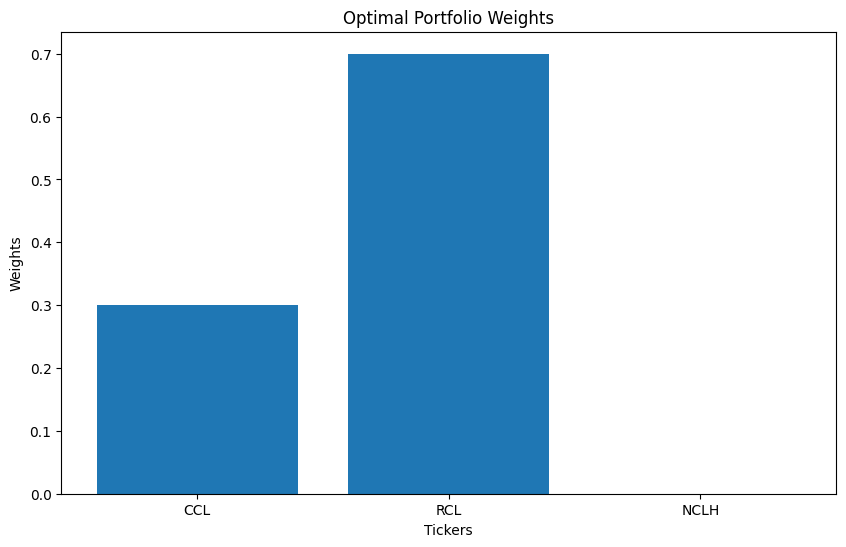

In [ ]:
#display the final portfolio in a plot

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.bar(tickers, optimized_weights)
plt.xlabel('Tickers')
plt.ylabel('Weights')
plt.title('Optimal Portfolio Weights')
plt.show()